In [27]:
import numpy as np

## Parameters

In [28]:
# Params (à mettre/modifier dans le plots.py)
S0 = 110
K = 105
r = 0.03
T = 1
kappa = 2
lambdA = 0
theta = 0.04
sig_0 = 0.2
sig_sig = 0.3
rho = -0.7
N=256
L =12

X = np.log(S0/K)

#print("kappa_star =", ks)
#print("theta_star =", ts)
#print("x =", X)


In [29]:
#src.cumul.py
def trunc_range(r,T,kappa,lambd,theta,sig_0,sig_sig,rho,L,x):
    """
    Calcule les cumulants  puis les bornes de l'intervalle de troncature.
    
      r: taux sans risque
      T: maturité
      kappa: vitesse de retour à la moyenne
      lambd: coefficient multiplicateur du prix du risque de volatilité
      theta: variance moyenne de long terme
      sig_0: volatilité initiale
      sig_sig: volatilité de la volatilité
      rho: corrélation entre les movements browniens
      L: largeur de l'intervalle de troncature
      x: ln(S0/K), avec S0 la valeur initiale du sous-jacent
    """

    kappa_star=kappa+lambd
    theta_star=kappa*theta/(kappa+lambd)

    c_1=r*T+ (1-np.exp(-kappa_star*T))*(theta_star-sig_0**2)/(2*kappa_star) -(1/2)*theta_star*T
    # par souci de lisibilité on sépare en 5 le calcul de c_2.
    A=sig_sig*T*kappa_star*np.exp(-kappa_star*T)*(sig_0**2-theta_star)*(8*kappa_star*rho-4*sig_sig)
    B=kappa_star*rho*sig_sig*(1-np.exp(-kappa_star*T))*(16*theta_star-8*sig_0**2)
    C=2*theta_star*kappa_star*T*(-4*kappa_star*rho*sig_sig+sig_sig**2+4*kappa_star**2)
    D=sig_sig**2*((theta_star-2*sig_0**2)*np.exp(-2*kappa_star*T)+theta_star*(6*np.exp(-kappa_star*T)-7)+2*sig_0**2)
    E=8*kappa_star**2*(sig_0**2-theta_star)*(1-np.exp(-kappa_star*T))
    c_2=(1/(8*kappa_star**3))*(A+B+C+D+E)

    a=x+c_1-L*np.sqrt(np.abs(c_2))
    b=x+c_1+L*np.sqrt(np.abs(c_2))
    return a, b, c_1, c_2

In [30]:
#src.carac.py
def carac_heston(omega, r, T, ks, ts, sig_0, sig_sig, rho):
  """ 
  Renvoie les valeurs de la fonction caractèristique sur la grille de valeurs omega
  omega: grille de valeurs d'abscisse
  r: taux sans risque
  T: maturité
  ks: kappa_star
  ts: theta_star
  sig_0: volatilité initiale
  sig_sig: volatilité de volatilité
  rho: corrélation des mouvemtns browniens
  
  """
  h = ks- 1j * rho * sig_sig * omega
  D = np.sqrt(h**2 + (omega**2+ 1j * omega)* sig_sig**2)
  G = (h-D)/(h+D)
  Exp1 = 1j * omega * r * T + ((sig_0**2)/(sig_sig**2))*((1-np.exp(-D*T))/(1-G*np.exp(-D*T))) * (h-D)

  Exp2 = (ks*ts/sig_sig**2) * (T*(h-D) - 2*np.log((1-G*np.exp(-D*T))/(1-G)))

  return np.exp(Exp1 + Exp2)


In [31]:
#src.U_k.py
def chi(omega, a,p,q) :
  """
  Renvoie la valeur de chi_k(p,q) pour le calcul des V_k

    omega: grille de valeurs
    a: borne basse de l'intervalle de troncature
    p: 0 pour un call, a pour un put
    q: b pour un call, 0 pour un put
  """

  chi_q = np.exp(q)*(np.cos(omega*(q-a)) +omega * np.sin(omega*(q-a)))
  chi_p = np.exp(p)*(np.cos(omega*(p-a)) +omega * np.sin(omega*(p-a)))

  return (chi_q-chi_p)/(1+omega**2)


def psi(omega,a,p,q) :
  """
  Renvoie la valeur des psi_k(p,q) pour le calcul des V_k

    omega: grille de valeurs
    a: borne basse de l'intervalle de troncature
    p: 0 pour un call, a pour un put
    q: b pour un call, 0 pour un put
  """

  res = np.empty_like(omega)
  
  res[0] = q-p
  w = omega[1:]
  res[1:] = (np.sin(w*(q-a)) - np.sin(w*(p-a)))/w

  return res

In [32]:
#src.fangoosterlee.py
def P(S0,K,T,r,kappa,lambdA,theta,sig_0,sig_sig,rho,N,L=12, call="False"):
  """
    renvoie le prix d'un call ou d'un put.

      S0: prix initial de l'actif,
      K: strike
      T: maturité,
      r: taux sans risque
      kappa: vitesse de retour à la moyenne
      lambdA: prix du risque de volatilité
      theta: variance moyenne de long terme
      sig_0:volatilité initiale
      sig_sig:volatilité de volatilité
      rho: corrélation des mouvements browniens
      N: nombre de coefficients cosinus gardés
      L: largeur de troncature
  """
  x=np.log(S0/K)
  k=np.arange(N)
  a,b,c_1,c_2=trunc_range(r,T,kappa,lambdA,theta,sig_0,sig_sig,rho,L,x)
  omega=k*np.pi/(b-a)
  kappa_star=kappa+lambdA
  theta_star=kappa*theta/kappa_star
  phi=carac_heston(omega,r,T,kappa_star,theta_star,sig_0,sig_sig,rho)
  Chi=chi(omega,a,a,0.0)
  Psi=psi(omega,a,a,0.0)
  U_k=2/(b-a)*(Psi-Chi)
  fact_e=np.exp(1j*omega*(x-a))
  termes=phi*U_k*fact_e
  poids=np.ones_like(omega)
  poids[0]=0.5
  somme=np.sum(poids*termes)
  prix_put=K*np.exp(-r*T)*np.real(somme)
  if call=="True":
    return prix_put+S0-K*np.exp(-r*T)
  else:
    return prix_put


In [33]:
prix=P(S0,K,T,r,kappa,lambdA,theta,sig_0,sig_sig,rho,N)
prix

np.float64(5.087334599073584)

In [34]:
# src.blackscholes.py
from scipy.stats import norm
def black_scholes(S0, K, r, T, sigma):
    """
    Renvoie (prix_put, prix_call) sans dividendes.
    """
    if S0 <= 0 or K <= 0:
        raise ValueError("S0 et K doivent être positifs.")

    if T < 0 or sigma < 0:
        raise ValueError("T et sigma doivent être positifs ou nuls.")

    # À l'échéance
    if T == 0:
        return max(K - S0, 0.0), max(S0 - K, 0.0)

    # Cas sans volatilité
    if sigma == 0:
        strike_actualise = K * np.exp(-r*T)
        return (
            max(strike_actualise - S0, 0.0),
            max(S0 - strike_actualise, 0.0)
        )

    d1 = (
        np.log(S0 / K) + (r + 0.5*sigma**2)*T
    ) / (sigma*np.sqrt(T))

    d2 = d1 - sigma*np.sqrt(T)

    call_bs = (
        S0*norm.cdf(d1)
        - K*np.exp(-r*T)*norm.cdf(d2)
    )

    put_bs = (
        K*np.exp(-r*T)*norm.cdf(-d2)
        - S0*norm.cdf(-d1)
    )

    return put_bs, call_bs

In [35]:
prix=P(S0,K,T,r,kappa,lambdA,theta,sig_0,sig_sig,rho,N)
put_bs, call_bs=black_scholes(S0,K,r,T,sig_0)
print(f"Prix Heston : {prix}")
print(f"prix Black-Scholes : {put_bs}")

Prix Heston : 5.087334599073584
prix Black-Scholes : 4.995644120438541


Vérification numérique que le modèle converge vers black-scholes quand la vol of vol tend vers 0:

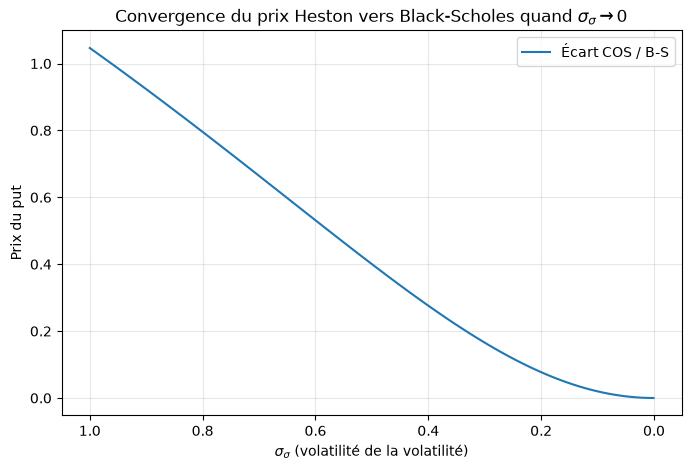

Écart avec B-S pour sig_sig = 0.001 : -2.01e-06


In [36]:
# transformer en fonction, mettre dans un fichier plots.py



import matplotlib.pyplot as plt

# Valeurs de sig_sig : de 1.0 (élevé, Feller violée) jusqu'à 0.001 (proche de 0)
# On s'arrête à 1e-3 : en dessous, l'annulation numérique dans (h-D)/sig_sig**2 dégrade le résultat
sig_sig_grid = np.linspace(1.0, 0.001, 100)

# Prix Heston (put) pour chaque sig_sig, les autres paramètres restant ceux de la cellule des paramètres
prix_heston = np.array([
    P(S0, K, T, r, kappa, lambdA, theta, sig_0, ss, 0, N)
    for ss in sig_sig_grid
])

# Asymptote : prix Black-Scholes (put) de volatilité sig_0 (valable car sig_0**2 = theta et lambdA = 0)
put_bs, _ = black_scholes(S0, K, r, T, sig_0)

plt.figure(figsize=(8, 5))
plt.plot(sig_sig_grid, np.abs(prix_heston-put_bs), label="Écart COS / B-S")
#plt.axhline(put_bs, color="red", linestyle="--", label=f"Asymptote : prix Black-Scholes = {put_bs:.4f}")
plt.gca().invert_xaxis()   # on lit le graphique de sig_sig élevé vers 0
plt.xlabel(r"$\sigma_\sigma$ (volatilité de la volatilité)")
plt.ylabel("Prix du put")
plt.title(r"Convergence du prix Heston vers Black-Scholes quand $\sigma_\sigma \to 0$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Écart avec B-S pour sig_sig = {sig_sig_grid[-1]:.3f} : {prix_heston[-1] - put_bs:.2e}")

In [37]:
# A cause d’une erreur dans l’affichage de nos graphes de nos précédents notebooks
# que nous n’avons pas réussi à résoudre dans les temps indiqués, nous avons préférés
# avoir recours à une IA à la dernière minute afin de tout de même pouvoir vous afficher nos graphes manquants dans le code,
# et non seulement dans le rapport.
# Ceci explique donc la non-authenticité des commentaires suivants
import mpmath as mp
mp.mp.dps = 40
S0=K=mp.mpf(100); T=mp.mpf(10); r=mp.mpf(0)
lam=mp.mpf('1.5768'); ubar=mp.mpf('0.0398'); u0=mp.mpf('0.0175')
eta=mp.mpf('0.5751'); rho=mp.mpf('-0.5711')

def phi(w):
    a = lam - 1j*rho*eta*w
    d = mp.sqrt(a**2 + (w**2 + 1j*w)*eta**2)
    g = (a - d)/(a + d)
    e = mp.e**(-d*T)
    return (mp.e**(1j*w*r*T + u0/eta**2*(1-e)/(1-g*e)*(a-d))
            * mp.e**(lam*ubar/eta**2*(T*(a-d) - 2*mp.log((1-g*e)/(1-g)))))

k = mp.log(S0/K) + r*T
f = lambda u: mp.re(mp.e**(1j*u*k)*phi(u-0.5j))/(u**2 + mp.mpf(1)/4)
I = mp.quad(f, [0,1,2,5,10,20,50,100,200,400,800,1600])
prix_exact = S0 - mp.sqrt(S0*K)*mp.e**(-r*T/2)/mp.pi*I
print(prix_exact)    # 5.785155434376189028140271
np.abs(prix_heston-prix_exact)

22.31894579115448917970685953908590144582


array([mpf('18.36978032881481570835878130158865369028892'),
       mpf('18.35759926405219555543955549940922773547019'),
       mpf('18.34536359334157029831023293657684243388023'),
       mpf('18.33307376945128586352827198273492521710243'),
       mpf('18.32073028713928975118439495266405410237159'),
       mpf('18.30833368503910774304064772726026839680518'),
       mpf('18.29588454761910243572107730718319780297126'),
       mpf('18.28338350721717853385304635442783600754585'),
       mpf('18.27083124615339160466807526821260816521491'),
       mpf('18.25822849892279309468155417410647041268195'),
       mpf('18.24557605447092923010974856727746791310157'),
       mpf('18.23287475855420270075389282131557828850593'),
       mpf('18.22012551618768883198005652805780536599006'),
       mpf('18.20732929418246060147955005807792312569465'),
       mpf('18.19448712377493071666710249549699491925086'),
       mpf('18.18160010334994802970574539206912285752143'),
       mpf('18.1686694012604433876451986

In [38]:
import time
# mettre dans src.plots.py les graphes en + (smile avec rho=0 à part, influence de rho sur la forme du smile...)
# Params (à mettre/modifier dans le plots.py)
S0 = 100 # actif prix initial
K = 100 # strike
r = 0.0 # taux sans risque
T = 10  # maturité
kappa = 1.5768 # vitesse de retour à la moyenne
lambdA = 0 # prix du risque de vol
theta = 0.0398 # variance moyenne de long terme
sig_0 = np.sqrt(0.0175) # vol initiale
sig_sig = 0.5751 #vol de vol
rho = -0.5711 # corrélation mvt browniens
N=64
L =32
times=[]
X = np.log(S0/K)

#print("kappa_star =", ks)
#print("theta_star =", ts)
#print("x =", X)
for i in range(100):
    start=time.time()
    prix_heston=P(S0, K, T, r, kappa, lambdA, theta, sig_0, sig_sig, rho, N)
    prix_heston
    end=time.time()
    times.append(np.abs(end-start))

In [39]:
n_runs = 100
resultats = {}
# modifier la valeur de L dans le second appel de P.
for N in [8,16,32,64,128,256,512]:
    P(S0, K, T, r, kappa, lambdA, theta, sig_0, sig_sig, rho, N)  # échauffement
    times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        prix_heston = P(S0, K, T, r, kappa, lambdA, theta, sig_0, sig_sig, rho, N,L=12)
        erreur=np.abs(prix_exact-prix_heston)
        times.append(time.perf_counter() - start)
    resultats[N] = (prix_heston, 1e3 * np.mean(times), 1e3 * np.std(times))
    print(f"N={N}: prix={prix_heston:.9f}, temps={1e3*np.mean(times):.3f} ms, erreur={erreur} "
          f"(écart-type {1e3*np.std(times):.3f} ms)")

N=8: prix=27.508718978, temps=0.113 ms, erreur=5.189773186991801898994464756166660123397 (écart-type 0.010 ms)
N=16: prix=22.980958781, temps=0.067 ms, erreur=0.6620129895577214742668110208493702941433 (écart-type 0.021 ms)
N=32: prix=22.313754852, temps=0.070 ms, erreur=0.005190938719332629279295468525863356064217 (écart-type 0.022 ms)
N=64: prix=22.318962218, temps=0.071 ms, erreur=0.00001642682855307132807127497168713145409314 (écart-type 0.009 ms)
N=128: prix=22.318945781, temps=0.084 ms, erreur=0.00000001013963169181740169581947392887915880869 (écart-type 0.006 ms)
N=256: prix=22.318945781, temps=0.108 ms, erreur=0.00000001023892648642619689629403418965186388681 (écart-type 0.009 ms)
N=512: prix=22.318945781, temps=0.157 ms, erreur=0.00000001023892648642619689629403418965186388681 (écart-type 0.004 ms)


In [40]:
10**(-4)*5.77

0.000577

<>:22: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:22: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\User\AppData\Local\Temp\ipykernel_22656\2093617361.py:22: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.semilogy(N_values, y_theo, '--', color='darkorange', label=f"Tendance théorique $\propto e^{{{coeffs[0]:.2f} N}}$")


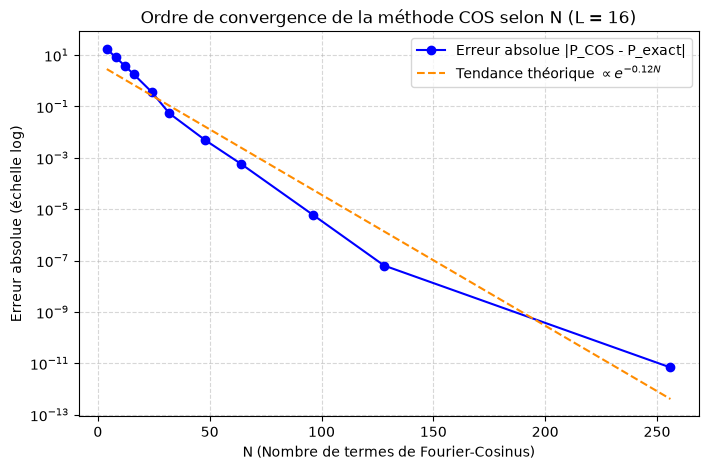

In [41]:

def plot_convergence_N():
    # Étape B : Étude de la convergence en fonction de N (à L fixe et grand)
    N_values = np.array([4, 8, 12, 16, 24, 32, 48, 64, 96, 128, 256])
    L_fixed = 16  

    errors_N = []
    for N_val in N_values:
        p_cos = P(S0, K, T, r, kappa, lambdA, theta, sig_0, sig_sig, rho, N=int(N_val), L=L_fixed)
        # Conversion explicite en float pour éviter les conflits avec les types mpf
        errors_N.append(float(abs(p_cos - prix_exact)))

    errors_N = np.array(errors_N)

    # Ajustement linéaire en échelle semi-log (log(erreur) = a * N + b)
    mask = errors_N > 1e-12
    coeffs = np.polyfit(N_values[mask], np.log(errors_N[mask]), 1)
    y_theo = np.exp(coeffs[1]) * np.exp(coeffs[0] * N_values)

    # Tracé
    plt.figure(figsize=(8, 5))
    plt.semilogy(N_values, errors_N, 'o-', color='b', label="Erreur absolue |P_COS - P_exact|")
    plt.semilogy(N_values, y_theo, '--', color='darkorange', label=f"Tendance théorique $\propto e^{{{coeffs[0]:.2f} N}}$")
    plt.xlabel("N (Nombre de termes de Fourier-Cosinus)")
    plt.ylabel("Erreur absolue (échelle log)")
    plt.title(f"Ordre de convergence de la méthode COS selon N (L = {L_fixed})")
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()
    plt.show()

plot_convergence_N()

<>:25: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:25: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\User\AppData\Local\Temp\ipykernel_22656\2852033392.py:25: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.semilogy(L_values, y_theo_L, '--', color='darkblue', label=f"Tendance théorique $\propto e^{{{coeffs_L[0]:.2f} L}}$")


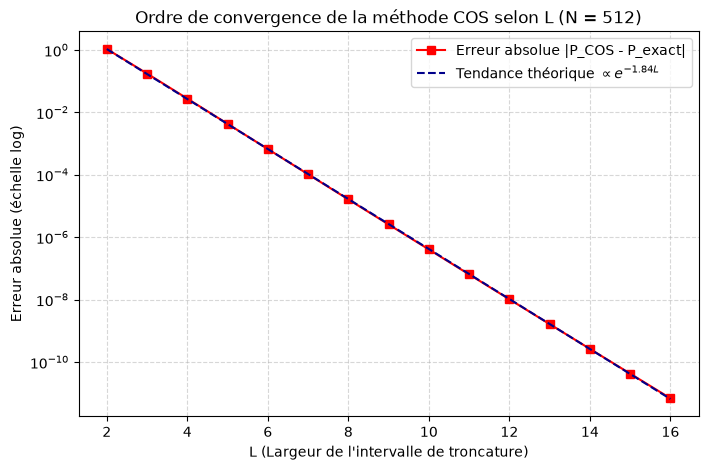

In [42]:
import numpy as np
import matplotlib.pyplot as plt

def plot_convergence_L():
    # Étape C : Étude de la convergence en fonction de L (à N fixe et grand)
    L_values = np.linspace(2, 16, 15)  
    N_fixed = 512  

    errors_L = []
    for L_val in L_values:
        p_cos = P(S0, K, T, r, kappa, lambdA, theta, sig_0, sig_sig, rho, N=N_fixed, L=L_val)
        # Conversion explicite en float pour éviter les conflits avec les types mpf
        errors_L.append(float(abs(p_cos - prix_exact)))

    errors_L = np.array(errors_L)

    # Ajustement linéaire en échelle semi-log pour la tendance e^{-\alpha L}
    mask_L = errors_L > 1e-12
    coeffs_L = np.polyfit(L_values[mask_L], np.log(errors_L[mask_L]), 1)
    y_theo_L = np.exp(coeffs_L[1]) * np.exp(coeffs_L[0] * L_values)

    # Tracé
    plt.figure(figsize=(8, 5))
    plt.semilogy(L_values, errors_L, 's-', color='r', label="Erreur absolue |P_COS - P_exact|")
    plt.semilogy(L_values, y_theo_L, '--', color='darkblue', label=f"Tendance théorique $\propto e^{{{coeffs_L[0]:.2f} L}}$")
    plt.xlabel("L (Largeur de l'intervalle de troncature)")
    plt.ylabel("Erreur absolue (échelle log)")
    plt.title(f"Ordre de convergence de la méthode COS selon L (N = {N_fixed})")
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()
    plt.show()
plot_convergence_L()

In [44]:
from scipy.optimize import brentq

def implied_volatility(price, S0, K, r, T, option_type="put"):
    """
    Calcule la volatilité implicite par la méthode de Brent en inversant 
    le modèle de Black-Scholes.
    
    Paramètres :
    - price : prix cible de l'option (ex: issu du modèle de Heston)
    - S0 : prix spot du sous-jacent
    - K : strike de l'option
    - r : taux sans risque
    - T : maturité
    - option_type : "put" ou "call"
    """
    def objective(sigma):
        # Utilisation de la fonction black_scholes définie dans le code source[cite: 1]
        put_bs, call_bs = black_scholes(S0, K, r, T, sigma)
        if option_type.lower() == "put":
            return put_bs - price
        else:
            return call_bs - price

    # Intervalle de recherche pour la volatilité (de 0.001% à 500%)
    try:
        implied_vol = brentq(objective, 1e-5, 5.0)
    except ValueError:
        # En cas d'échec de convergence (prix hors des bornes arbitraires)
        implied_vol = np.nan
        
    return implied_vol

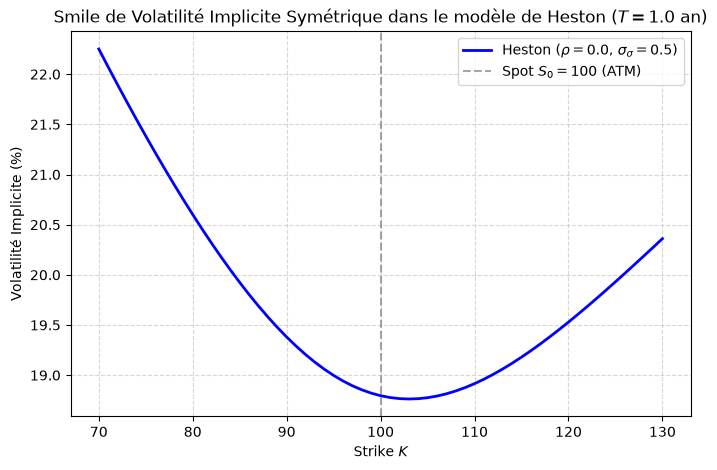

In [45]:
import numpy as np
import matplotlib.pyplot as plt

def smile_symetrique():
    S0_smile = 100
    r_smile = 0.03
    T_smile = 1.0
    kappa_smile = 2.0
    lambdA_smile = 0.0
    theta_smile = 0.04       # Volatilité moyen terme de 20%
    sig_0_smile = 0.2        # Volatilité initiale de 20%
    
    # MODIFICATIONS CLÉS POUR LE SMILE EN "U" :
    rho_smile = 0.0          # Corrélation nulle -> Symétrie parfaite autour de S0
    sig_sig_smile = 0.5      # Vol of Vol plus forte -> Courbure / "U" bien marqué
    
    N_smile = 256
    L_smile = 12
    
    # Grille de Strikes K (de 70 à 130 autour du prix SPOT S0=100)
    K_grid = np.linspace(70, 130, 61)
    vols_implicites = []
    
    for K_val in K_grid:
        price_heston = P(S0_smile, K_val, T_smile, r_smile, kappa_smile, 
                         lambdA_smile, theta_smile, sig_0_smile, sig_sig_smile, 
                         rho_smile, N_smile, L_smile, call="False")
        
        vol_imp = implied_volatility(price_heston, S0_smile, K_val, r_smile, T_smile, option_type="put")
        vols_implicites.append(vol_imp * 100) # Conversion en %
        
    plt.figure(figsize=(8, 5))
    plt.plot(K_grid, vols_implicites, 'b-', linewidth=2, label=rf"Heston ($\rho = {rho_smile}$, $\sigma_\sigma = {sig_sig_smile}$)")
    plt.axvline(S0_smile, color='gray', linestyle='--', alpha=0.7, label=f"Spot $S_0 = {S0_smile}$ (ATM)")
    
    plt.xlabel("Strike $K$")
    plt.ylabel("Volatilité Implicite (%)")
    plt.title(f"Smile de Volatilité Implicite Symétrique dans le modèle de Heston ($T = {T_smile}$ an)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.show()
smile_symetrique()